# Масштаб: обучение и внутренние представления

Семь последних checkpoints; история вероятностей по всем эпохам. Обучение не запускается.
Графики и численные результаты сохраняются рядом с исходными результатами, в `analysis/`.
Исходные веса, данные и обучающие ноутбуки не изменяются.

In [1]:
from pathlib import Path
import sys, os, json, csv, time, hashlib
import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
RESULTS = ROOT / 'results' / 'letters_scale_epochwise'
OUT = RESULTS / 'analysis'
OUT.mkdir(exist_ok=True)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from model import DeiTTiny

plt.rcParams.update({'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 110})
def savefig(fig, name):
    fig.savefig(OUT / (name + '.png'), dpi=170, bbox_inches='tight')
    display(fig)
    plt.close(fig)


## Обучение и перенос на большую H

Вероятности в NPZ содержат все эпохи семи условий. CSV сохранились только для последних двух запусков; их используем дополнительно, не восстанавливая отсутствующий train/validation из теста. Все кривые ниже — сохранённые предсказания, без повторного обучения.


In [2]:
import ast
from matplotlib.ticker import PercentFormatter

files = sorted(RESULTS.glob("big_*_probabilities.npz"))
runs = [p.stem.replace("_probabilities", "") for p in files]
counts = [int(run.split("_")[-1]) for run in runs]
colors = dict(zip(runs, plt.cm.tab10(np.arange(len(runs)))))
curves, summaries, final_distributions = {}, {}, []

for path, run, count in zip(files, runs, counts):
    with np.load(path, allow_pickle=False) as z:
        p = z["probabilities"]
        labels, heights = z["labels"], z["heights"]
        classes, donors = z["classes"].tolist(), z["donors"].tolist()
        epochs = z["epochs"]
        assert p.ndim == 3 and p.shape[1:] == (len(labels), len(classes))
        assert np.array_equal(epochs, np.arange(1, len(p) + 1))
        assert classes == list("ABCDEFGHIJKLMNOPQRSTUVWXYZ") and len(donors) == count
        assert "H" not in donors and int(z["seed"]) == 42
        assert z["shifts"].shape == (len(labels), 2)
        assert np.isfinite(p).all() and p.min() >= 0 and p.max() <= 1
        assert np.allclose(p.sum(-1), 1, atol=2e-6)
        small, large = heights == 64, heights == 128
        h = classes.index("H")
        assert small.sum() == 26 * 256 and large.sum() == 256
        assert np.all(labels[large] == h)
        assert np.array_equal(np.bincount(labels[small], minlength=26), np.full(26, 256))
        small_only_other = [i for i, c in enumerate(classes) if c not in donors and c != "H"]
        train_counts = z["train_counts"]
        assert train_counts.shape == (26, 2) and train_counts[h, 1] == 0
        values = {name: [] for name in ["small_accuracy", "h_recall", "small_ptrue", "h_ptrue",
                                       "small_ce", "h_ce", "h_entropy", "h_relative"]}
        for pe in p:
            predicted = pe.argmax(-1)
            pt = pe[np.arange(len(labels)), labels]
            logp = np.log(np.maximum(pe[large], 1e-38))
            values["small_accuracy"].append(np.mean(predicted[small] == labels[small]))
            values["h_recall"].append(np.mean(predicted[large] == h))
            values["small_ptrue"].append(pt[small].mean())
            values["h_ptrue"].append(pt[large].mean())
            values["small_ce"].append(-np.log(np.maximum(pt[small], 1e-38)).mean())
            values["h_ce"].append(-np.log(np.maximum(pt[large], 1e-38)).mean())
            values["h_entropy"].append(-(pe[large] * logp).sum(-1).mean())
            denominator = pe[large][:, small_only_other].mean() if small_only_other else np.nan
            values["h_relative"].append(pt[large].mean() / denominator if denominator > 0 else np.nan)
        curves[run] = {key: np.asarray(value) for key, value in values.items()}
        curves[run]["epochs"] = epochs.copy()
        predicted_counts = np.bincount(p[-1, large].argmax(-1), minlength=26)
        summaries[run] = {"donor_count": count, "epoch": int(epochs[-1]),
                          **{key: float(value[-1]) for key, value in values.items()},
                          "predictions": {c: int(n) for c, n in zip(classes, predicted_counts) if n}}
        final_distributions.append(p[-1, large].mean(0))
    del p
final_distributions = np.stack(final_distributions)

# Безопасный разбор напечатанных результатов: заменяется только литерал nan.
class NanLiteral(ast.NodeTransformer):
    def visit_Name(self, node):
        if node.id == "nan":
            return ast.copy_location(ast.Constant(value=None), node)
        raise ValueError(f"Unexpected name: {node.id}")

printed = ROOT / "data" / "outputs" / "data.txt"
reference = ast.literal_eval(NanLiteral().visit(ast.parse(printed.read_text(encoding="utf-8"), mode="eval")))
with (RESULTS / "metrics.csv").open(newline="", encoding="utf-8") as f:
    reference += list(csv.DictReader(f))
checked = set()
for row in reference:
    run = row["run"]
    assert run in summaries and int(row["epochs"]) == summaries[run]["epoch"]
    for old, new in [("small_accuracy", "small_accuracy"), ("large_recall", "h_recall"),
                     ("small_true_confidence", "small_ptrue"), ("large_true_confidence", "h_ptrue"),
                     ("large_loss", "h_ce"), ("large_entropy", "h_entropy")]:
        assert np.isclose(float(row[old]), summaries[run][new], rtol=2e-5, atol=2e-6), (run, old)
    checked.add(run)
assert checked == set(runs)
print("Проверено: все 7 архивов, метаданные, нормировка вероятностей и итоговые метрики.")
print("Доноры | эпоха | accuracy small | recall H | mean p(H) | предсказания большой H")
for run in runs:
    s = summaries[run]
    print(f"{s['donor_count']:>6} | {s['epoch']:>5} | {s['small_accuracy']:>13.4%} | "
          f"{s['h_recall']:>8.1%} | {s['h_ptrue']:.7f} | {s['predictions']}")

Проверено: все 7 архивов, метаданные, нормировка вероятностей и итоговые метрики.
Доноры | эпоха | accuracy small | recall H | mean p(H) | предсказания большой H
     0 |    90 |     100.0000% |     0.0% | 0.0000407 | {'M': 256}
     1 |   100 |     100.0000% |     0.0% | 0.0000004 | {'A': 256}
     5 |   120 |      99.9249% |     0.0% | 0.0045020 | {'B': 228, 'D': 28}
    10 |    90 |     100.0000% |     0.0% | 0.0005805 | {'B': 248, 'K': 8}
    15 |   120 |      98.6178% |     0.0% | 0.0001806 | {'B': 100, 'D': 1, 'K': 153, 'M': 1, 'N': 1}
    20 |    95 |     100.0000% |     0.0% | 0.0039572 | {'B': 28, 'N': 193, 'R': 35}
    25 |   100 |      99.9700% |     0.0% | 0.0005585 | {'B': 256}


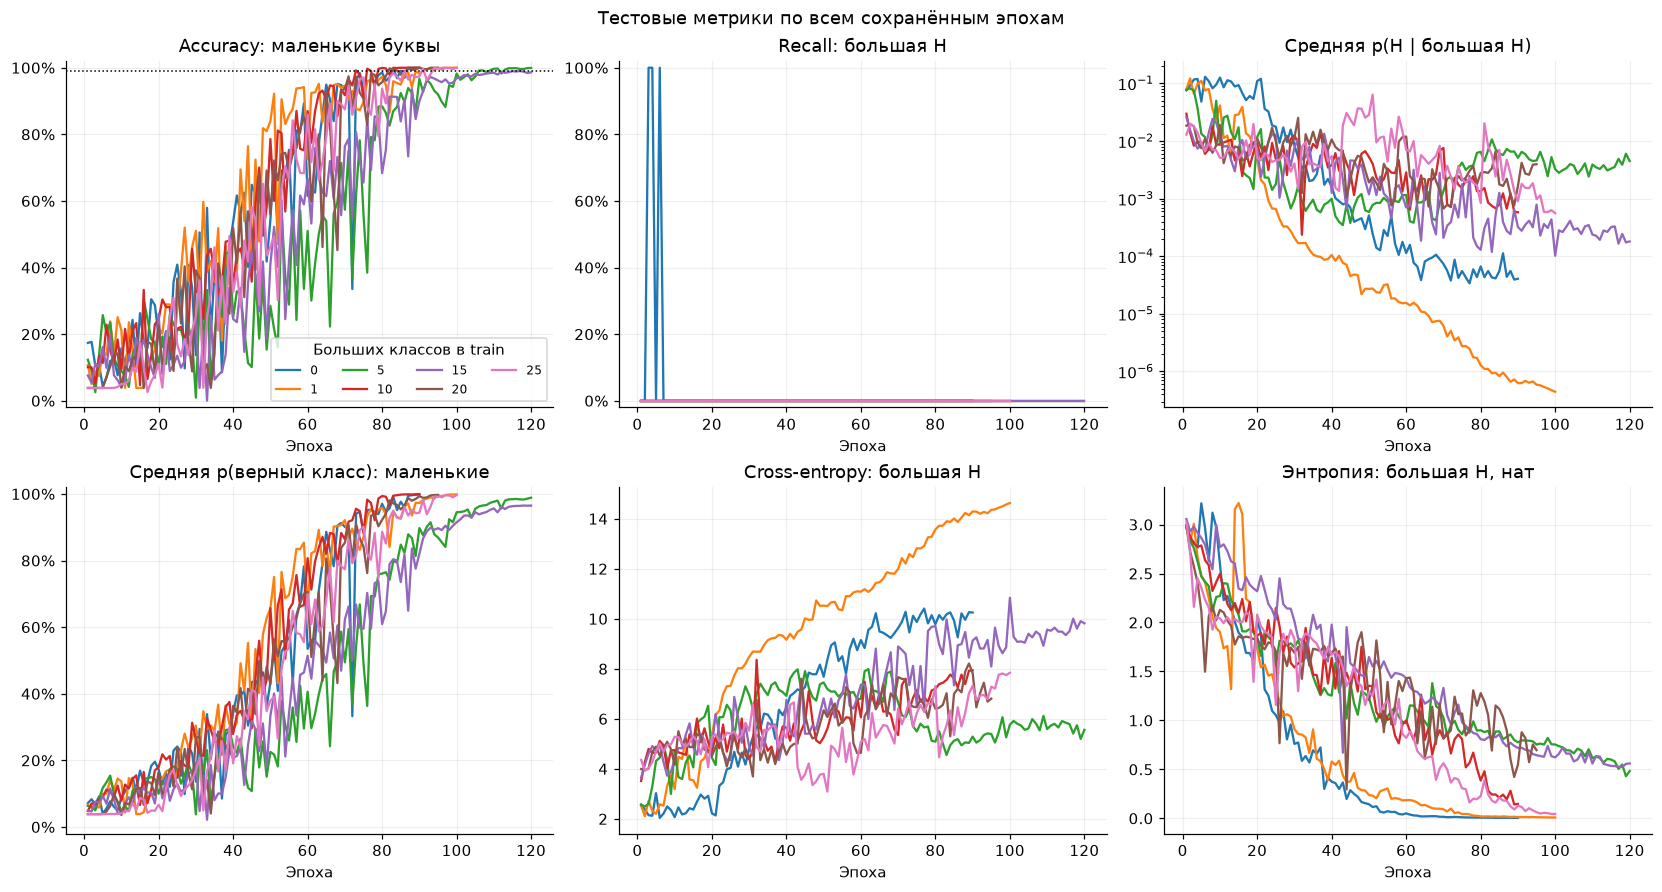

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
panels = [("small_accuracy", "Accuracy: маленькие буквы"), ("h_recall", "Recall: большая H"),
          ("h_ptrue", "Средняя p(H | большая H)"), ("small_ptrue", "Средняя p(верный класс): маленькие"),
          ("h_ce", "Cross-entropy: большая H"), ("h_entropy", "Энтропия: большая H, нат")]
for ax, (metric, title) in zip(axes.flat, panels):
    for run, count in zip(runs, counts):
        ax.plot(curves[run]["epochs"], curves[run][metric], color=colors[run], label=str(count), lw=1.5)
    ax.set(title=title, xlabel="Эпоха")
    ax.grid(alpha=.2)
    if metric in ("small_accuracy", "h_recall", "small_ptrue"):
        ax.yaxis.set_major_formatter(PercentFormatter(1))
        ax.set_ylim(-.02, 1.02)
    if metric == "small_accuracy":
        ax.axhline(.99, color="black", ls=":", lw=1)
    if metric == "h_ptrue":
        ax.set_yscale("log")
axes[0, 0].legend(title="Больших классов в train", ncol=4, fontsize=8)
fig.suptitle("Тестовые метрики по всем сохранённым эпохам")
savefig(fig, "training_curves")

100% recall большой H на эпохах 3–4 условия `big_00` не означает успешного переноса: accuracy маленьких букв тогда составляет лишь 10.55–10.83%. На эпохе 3 модель предсказывает H для 3399 из 6656 маленьких изображений. После достижения 99% accuracy маленьких букв recall большой H равен нулю.

Дополнительная относительная метрика ниже: **средняя p(H) / средняя p(одного другого класса, который обучался только маленьким)**. Обе части считаются на одних и тех же изображениях большой H; в знаменателе усредняются и изображения, и подходящие классы. Это отношение, а не вероятность. Усреднение по классам учитывает изменение размера группы. Для 25 доноров таких других классов не остаётся, поэтому отношение не определено. Изменяется и состав группы, поэтому это дополнительная диагностика, а не самостоятельная мера обобщения.


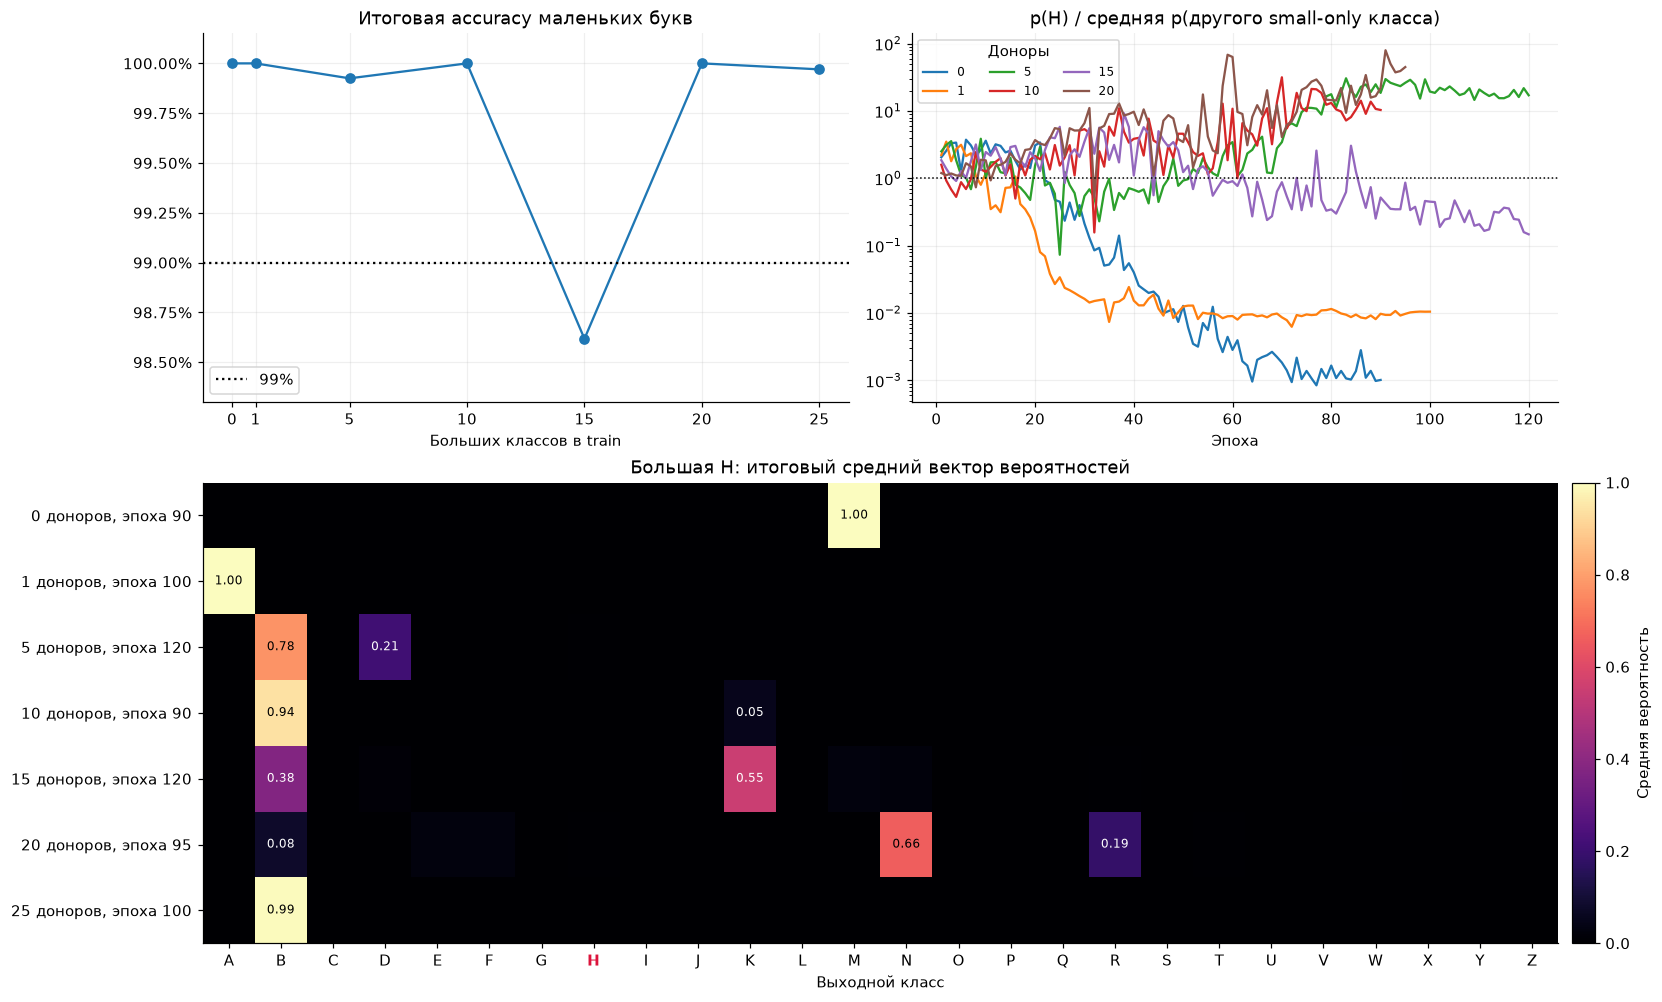

In [4]:
fig = plt.figure(figsize=(15, 9), constrained_layout=True)
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.25])
a1, a2, a3 = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, :])
a1.plot(counts, [summaries[r]["small_accuracy"] for r in runs], "o-", color="tab:blue")
a1.axhline(.99, color="black", ls=":", label="99%")
a1.set(title="Итоговая accuracy маленьких букв", xlabel="Больших классов в train", xticks=counts,
       ylim=(.983, 1.0015))
a1.yaxis.set_major_formatter(PercentFormatter(1))
a1.grid(alpha=.2)
a1.legend()
for run, count in zip(runs, counts):
    if count < 25:
        a2.plot(curves[run]["epochs"], curves[run]["h_relative"], color=colors[run], label=str(count))
a2.axhline(1, color="black", ls=":", lw=1)
a2.set(title="p(H) / средняя p(другого small-only класса)", xlabel="Эпоха", yscale="log")
a2.legend(title="Доноры", ncol=3, fontsize=8)
a2.grid(alpha=.2)
im = a3.imshow(final_distributions, aspect="auto", vmin=0, vmax=1, cmap="magma")
a3.set(xticks=np.arange(26), xticklabels=list("ABCDEFGHIJKLMNOPQRSTUVWXYZ"), yticks=np.arange(len(runs)),
       yticklabels=[f"{c} доноров, эпоха {summaries[r]['epoch']}" for r, c in zip(runs, counts)],
       xlabel="Выходной класс", title="Большая H: итоговый средний вектор вероятностей")
for tick in a3.get_xticklabels():
    if tick.get_text() == "H":
        tick.set_color("crimson"); tick.set_fontweight("bold")
for i, row in enumerate(final_distributions):
    for j, value in enumerate(row):
        if value >= .03:
            a3.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8,
                    color="black" if value > .65 else "white")
fig.colorbar(im, ax=a3, label="Средняя вероятность", fraction=.02, pad=.01)
savefig(fig, "final_predictions")

Для условий 20 и 25 доноров сохранились также train/validation-кривые. Итоговые validation accuracy у обоих — 100%, а recall большой H — 0%. Условия не достигали одинакового состояния обучения: например, 15 доноров завершились при 98.62% accuracy маленьких тестовых букв.


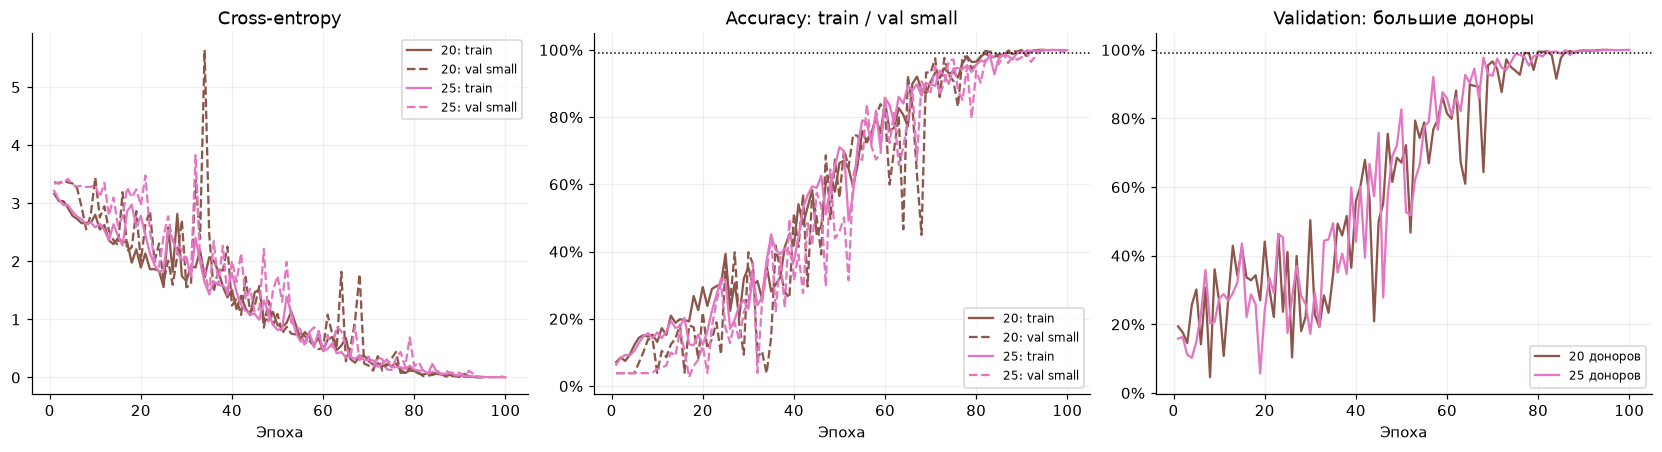

In [5]:
with (RESULTS / "history.csv").open(newline="", encoding="utf-8") as f:
    history = list(csv.DictReader(f))
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for run in sorted({r["run"] for r in history}):
    rows = [r for r in history if r["run"] == run]
    epochs = [int(r["epoch"]) for r in rows]
    count = int(run.split("_")[-1])
    axes[0].plot(epochs, [float(r["train_loss"]) for r in rows], color=colors[run], label=f"{count}: train")
    axes[0].plot(epochs, [float(r["val_small_loss"]) for r in rows], color=colors[run], ls="--", label=f"{count}: val small")
    axes[1].plot(epochs, [float(r["train_accuracy"]) for r in rows], color=colors[run], label=f"{count}: train")
    axes[1].plot(epochs, [float(r["val_small_accuracy"]) for r in rows], color=colors[run], ls="--", label=f"{count}: val small")
    axes[2].plot(epochs, [float(r["val_donor_large_accuracy"]) for r in rows], color=colors[run], label=f"{count} доноров")
for ax, title in zip(axes, ["Cross-entropy", "Accuracy: train / val small", "Validation: большие доноры"]):
    ax.set(title=title, xlabel="Эпоха")
    ax.grid(alpha=.2)
    ax.legend(fontsize=8)
for ax in axes[1:]:
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.axhline(.99, color="black", ls=":", lw=1)
savefig(fig, "training_validation")

## Сравнение представлений

Для каждой буквы берём 64 одинаковых сдвига на двух размерах. Это подвыборка test-координат
больших букв; для маленьких часть этих координат встречалась при обучении. Поэтому это
согласованная диагностическая выборка, а исходный test выше остаётся основным измерением качества.
На каждом из 12 блоков снимаем CLS; последняя, 13-я точка — финальный LayerNorm.

- **RSA:** корреляция Спирмена между 325 попарными расстояниями букв на двух масштабах.
  Перед cosine-distance представления центрируются по буквам отдельно для каждого масштаба.
  Это сравнивает отношения между классами, а не один общий фон активации.
- **Ближайший прототип:** маленькие прототипы строятся по 32 сдвигам, большие буквы проверяются
  на других 32. Общий центр берётся только по маленьким прототипам. Метрика не равна accuracy классификатора.
- **Перенос общего вектора:** `delta = mean(z_large - z_small)` только по буквам-донорам и первым 32 сдвигам.
  Из больших H на остальных сдвигах вычитаем delta; проверяем прототипы и исходный классификатор.
  H не участвует в оценке delta. Это диагностическое вмешательство, а не переобучение модели.

Контроли: сеть до обучения (seed=42), пиксели и бинарная карта занятых патчей.
Дополнительно из рангов расстояний регрессией удаляем связь с пиксельной геометрией,
занятостью патчей, количеством белого и шириной буквы. Это проверка чувствительности;
она может удалить и полезную информацию о форме и не доказывает отсутствие геометрических confounders.

Метод RSA: [Kriegeskorte et al., 2008](https://www.frontiersin.org/journals/systems-neuroscience/articles/10.3389/neuro.06.004.2008/full).
Перестановочные полосы ниже — случайное соответствие букв, а не доверительные интервалы между запусками.

In [6]:
assert torch.cuda.is_available(), 'Для снятия активаций нужна CUDA.'
DEVICE = torch.device('cuda')
torch.set_num_threads(2)
data = torch.load(ROOT / 'data' / 'letters.pt', map_location='cpu', weights_only=True)
LETTERS = data['letters']
H_INDEX = LETTERS.index('H')
templates = data['images'].to(DEVICE, dtype=torch.float32).div(255)
N_POS = 64
HALF = N_POS // 2
rng = np.random.default_rng(20261103)
paired_shifts = data['shift_pools'][1]['test'][rng.choice(256, N_POS, replace=False)]
for xmin, xmax, ymin, ymax in data['shift_bounds']:
    assert ((paired_shifts[:, 0] >= xmin) & (paired_shifts[:, 0] <= xmax)).all()
    assert ((paired_shifts[:, 1] >= ymin) & (paired_shifts[:, 1] <= ymax)).all()
labels_probe = torch.arange(26).repeat_interleave(2 * N_POS)
sizes_probe = torch.arange(2).repeat_interleave(N_POS).repeat(26)
shifts_probe = paired_shifts.repeat(52, 1)
layers = [str(i) for i in range(1, 13)] + ['LN']

def shifted_batch(labels, sizes, shifts):
    source = templates[labels.to(DEVICE), sizes.to(DEVICE)]
    shifts = shifts.to(DEVICE, dtype=torch.long)
    b, c, h, w = source.shape
    x = torch.arange(w, device=DEVICE)[None, None, :] - shifts[:, 0, None, None]
    y = torch.arange(h, device=DEVICE)[None, :, None] - shifts[:, 1, None, None]
    valid = (x >= 0) & (x < w) & (y >= 0) & (y < h)
    indices = (y.clamp(0, h-1) * w + x.clamp(0, w-1)).reshape(b, 1, h*w)
    result = source.flatten(2).gather(2, indices).reshape(b, c, h, w)
    return result.masked_fill(~valid[:, None], 0).expand(-1, 3, -1, -1)

def unit(x):
    return x / np.maximum(np.linalg.norm(x, axis=-1, keepdims=True), 1e-12)

def rdm(x):
    x = unit(x.astype(np.float64) - x.mean(axis=0, keepdims=True))
    return 1 - x @ x.T

UPPER = np.triu_indices(26, 1)
def ranks(x):
    _, inverse, counts = np.unique(x, return_inverse=True, return_counts=True)
    ends = np.cumsum(counts)
    return ((ends - counts + ends - 1) / 2)[inverse]

def correlation(a, b):
    a, b = a - np.mean(a), b - np.mean(b)
    denominator = np.linalg.norm(a) * np.linalg.norm(b)
    return float(a @ b / denominator) if denominator > 1e-12 else np.nan

def rsa(a, b):
    return correlation(ranks(a[UPPER]), ranks(b[UPPER]))

print(torch.cuda.get_device_name(), '| paired shifts:', N_POS)


NVIDIA GeForce RTX 4060 Laptop GPU | paired shifts: 64


In [7]:
pixel_means = np.zeros((26, 2, 224 * 224), dtype=np.float64)
occupancy_means = np.zeros((26, 2, 196), dtype=np.float64)
geometry = np.zeros((26, 2, 4), dtype=np.float64)
for start in range(0, len(labels_probe), 32):
    ll, ss = labels_probe[start:start+32], sizes_probe[start:start+32]
    x = shifted_batch(ll, ss, shifts_probe[start:start+32])[:, 0]
    foreground = x > (1 / 255)
    occupied = foreground.reshape(-1, 14, 16, 14, 16).any(4).any(2).flatten(1)
    for j, (label, size) in enumerate(zip(ll.tolist(), ss.tolist())):
        pixel_means[label, size] += x[j].flatten().cpu().numpy() / N_POS
        occupancy_means[label, size] += occupied[j].cpu().numpy() / N_POS
        coordinates = torch.where(foreground[j])
        geometry[label, size] += np.array([x[j].sum().item(), foreground[j].sum().item(),
                                          occupied[j].sum().item(),
                                          (coordinates[1].max()-coordinates[1].min()+1).item()]) / N_POS
pixel_rdms = np.stack([rdm(pixel_means[:, s]) for s in range(2)])
occupancy_rdms = np.stack([rdm(occupancy_means[:, s]) for s in range(2)])
controls = [np.ones(len(UPPER[0]))]
for s in range(2):
    controls += [ranks(pixel_rdms[s][UPPER]), ranks(occupancy_rdms[s][UPPER])]
    for k in range(4):
        value = geometry[:, s, k]
        controls.append(ranks(np.abs(value[:, None] - value[None, :])[UPPER]))
controls = np.column_stack(controls)
controls[:, 1:] = (controls[:, 1:] - controls[:, 1:].mean(0)) / np.maximum(controls[:, 1:].std(0), 1e-12)
controls_pinv = np.linalg.pinv(controls)
def residual_ranks(matrix):
    values = ranks(matrix[UPPER])
    return values - controls @ (controls_pinv @ values)

permutations = np.stack([rng.permutation(26) for _ in range(1000)])
print('RSA pixels:', round(rsa(*pixel_rdms), 3),
      '| occupied patches:', round(rsa(*occupancy_rdms), 3))


RSA pixels: 0.866 | occupied patches: 0.78


In [8]:
def summarize_features(features, logits, donor_ids, classifier):
    # [layer, letter, size, shift, feature]
    means = features.mean(axis=3)
    prototypes = features[:, :, 0, :HALF].mean(axis=2)
    origin = prototypes.mean(axis=1, keepdims=True)
    small_units = unit(prototypes - origin)
    large_test = features[:, :, 1, HALF:]
    scores = np.einsum('lcpd,lqd->lcpq', unit(large_test-origin[:, :, None]), small_units)
    nearest = scores.argmax(axis=-1)
    retrieval = (nearest == np.arange(26)[None, :, None]).mean(axis=2)
    small_test = features[:, :, 0, HALF:]
    small_scores = np.einsum('lcpd,lqd->lcpq', unit(small_test-origin[:, :, None]), small_units)
    small_retrieval = (small_scores.argmax(-1) == np.arange(26)[None, :, None]).mean(axis=2)
    h_scores = scores[:, H_INDEX].mean(axis=1)
    h_rank = 1 + (scores[:, H_INDEX] > scores[:, H_INDEX, :, H_INDEX, None]).sum(axis=-1).mean(axis=1)
    other_scores = scores[:, H_INDEX].copy()
    other_scores[:, :, H_INDEX] = -np.inf
    h_margin = (scores[:, H_INDEX, :, H_INDEX] - other_scores.max(axis=-1)).mean(axis=1)
    h_false_positive = (nearest[:, np.arange(26) != H_INDEX] == H_INDEX).mean(axis=(1, 2))
    matrices = np.stack([[rdm(means[l, :, s]) for s in range(2)] for l in range(13)])
    rsa_values, rsa_partial, null_bounds, reliability = [], [], [], []
    for l, (a, b) in enumerate(matrices):
        rsa_values.append(rsa(a, b))
        rsa_partial.append(correlation(residual_ranks(a), residual_ranks(b)))
        null = np.array([rsa(a, b[p][:, p]) for p in permutations])
        null_bounds.append(np.quantile(null, [0.025, 0.975]))
        reliability.append([rsa(rdm(features[l, :, s, :HALF].mean(1)),
                                rdm(features[l, :, s, HALF:].mean(1))) for s in range(2)])
    corrected_retrieval = np.full((13, 26), np.nan)
    corrected_h_scores = np.full((13, 26), np.nan)
    direction_cosine = np.full(13, np.nan)
    correction_h_recall = np.nan
    correction_h_p = np.nan
    if len(donor_ids):
        delta = (features[:, donor_ids, 1, :HALF] - features[:, donor_ids, 0, :HALF]).mean(axis=(1, 2))
        corrected = large_test - delta[:, None, None]
        corrected_scores = np.einsum('lcpd,lqd->lcpq', unit(corrected-origin[:, :, None]), small_units)
        corrected_retrieval = (corrected_scores.argmax(-1) == np.arange(26)[None, :, None]).mean(2)
        corrected_h_scores = corrected_scores[:, H_INDEX].mean(1)
        h_delta = (features[:, H_INDEX, 1, HALF:]-features[:, H_INDEX, 0, HALF:]).mean(1)
        direction_cosine = (unit(h_delta)*unit(delta)).sum(-1)
        weight = classifier.weight.detach().cpu().numpy()
        bias = classifier.bias.detach().cpu().numpy()
        corrected_logits = corrected[-1, H_INDEX] @ weight.T + bias
        probabilities = np.exp(corrected_logits - corrected_logits.max(-1, keepdims=True))
        probabilities /= probabilities.sum(-1, keepdims=True)
        correction_h_recall = (probabilities.argmax(-1) == H_INDEX).mean()
        correction_h_p = probabilities[:, H_INDEX].mean()
    return dict(means=means, rdms=matrices, rsa=np.array(rsa_values), partial_rsa=np.array(rsa_partial),
                null_bounds=np.array(null_bounds), reliability=np.array(reliability),
                retrieval=retrieval, small_retrieval=small_retrieval, h_scores=h_scores,
                h_rank=h_rank, h_margin=h_margin, h_false_positive=h_false_positive,
                corrected_retrieval=corrected_retrieval,
                corrected_h_scores=corrected_h_scores, direction_cosine=direction_cosine,
                classifier_accuracy=(logits.argmax(-1) == np.arange(26)[:, None, None]).mean(-1),
                corrected_h_recall=float(correction_h_recall), corrected_h_p=float(correction_h_p),
                raw_h_recall=float((logits[H_INDEX, 1, HALF:].argmax(-1) == H_INDEX).mean()))


In [9]:
representation_runs = ['initial'] + [p.stem for p in sorted(RESULTS.glob('big_*.pt'))]
representations = {}
provenance = {}
for run in representation_runs:
    started = time.perf_counter()
    torch.manual_seed(42)
    model = DeiTTiny(num_classes=26).to(DEVICE).eval()
    donors, epoch = '', 0
    if run != 'initial':
        path = RESULTS / (run + '.pt')
        checkpoint = torch.load(path, map_location='cpu', weights_only=True)
        assert checkpoint['letters'] == LETTERS
        model.load_state_dict(checkpoint['state_dict'], strict=True)
        donors, epoch = checkpoint['donors'], checkpoint['epoch']
        provenance[run] = dict(epoch=epoch, donors=donors, sha256=hashlib.sha256(path.read_bytes()).hexdigest())
    captured = []
    def capture(module, inputs, output):
        captured.append(output[:, 0].detach().cpu().numpy().copy())
    handles = [block.register_forward_hook(capture) for block in model.blocks]
    handles.append(model.norm.register_forward_hook(capture))
    chunks, output_chunks = [], []
    with torch.inference_mode():
        for start in range(0, len(labels_probe), 32):
            captured.clear()
            x = shifted_batch(labels_probe[start:start+32], sizes_probe[start:start+32], shifts_probe[start:start+32])
            logits = model(x)
            chunks.append(np.stack(captured))
            output_chunks.append(logits.cpu().numpy())
    for handle in handles:
        handle.remove()
    features = np.concatenate(chunks, axis=1).reshape(13, 26, 2, N_POS, 192)
    logits = np.concatenate(output_chunks).reshape(26, 2, N_POS, 26)
    assert np.isfinite(features).all() and np.isfinite(logits).all()
    donor_ids = np.array([LETTERS.index(c) for c in donors], dtype=int)
    representations[run] = summarize_features(features, logits, donor_ids, model.classifier)
    if run != 'initial':
        # The checkpoint must reproduce its archived final probabilities on these exact large-H shifts.
        archive = np.load(RESULTS / (run + '_probabilities.npz'))
        assert int(archive['epochs'][-1]) == epoch
        h_mask = (archive['labels'] == H_INDEX) & (archive['heights'] == 128)
        archive_shifts = archive['shifts'][h_mask]
        indices = [np.flatnonzero((archive_shifts == s.numpy()).all(1)).item() for s in paired_shifts]
        expected = archive['probabilities'][-1, h_mask][indices]
        actual = torch.tensor(logits[H_INDEX, 1]).softmax(-1).numpy()
        error = float(np.abs(expected-actual).max())
        assert np.allclose(expected, actual, atol=3e-5, rtol=3e-4), (run, error)
        provenance[run]['max_probability_error'] = error
        archive.close()
    print(run, 'epoch', epoch, '| RSA last', round(representations[run]['rsa'][-1], 3),
          '| H prototype rank', round(representations[run]['h_rank'][-1], 1),
          '| seconds', round(time.perf_counter()-started, 1), flush=True)
    del model, features, chunks, output_chunks
    torch.cuda.empty_cache()

arrays = {f'{run}__{key}': value for run, result in representations.items() for key, value in result.items()}
np.savez_compressed(OUT / 'representations.npz', **arrays, paired_shifts=paired_shifts.numpy(),
                    layers=np.array(layers), letters=np.array(list(LETTERS)),
                    pixel_rdms=pixel_rdms, occupancy_rdms=occupancy_rdms, geometry=geometry)
(OUT / 'provenance.json').write_text(json.dumps(provenance, indent=2), encoding='utf-8')


initial epoch 0 | RSA last 0.979 | H prototype rank 3.2 | seconds 4.3
big_00 epoch 90 | RSA last 0.104 | H prototype rank 6.2 | seconds 4.3
big_01 epoch 100 | RSA last 0.054 | H prototype rank 18.0 | seconds 4.3
big_05 epoch 120 | RSA last 0.038 | H prototype rank 6.8 | seconds 4.3
big_10 epoch 90 | RSA last 0.179 | H prototype rank 4.0 | seconds 4.3
big_15 epoch 120 | RSA last 0.553 | H prototype rank 16.8 | seconds 4.3
big_20 epoch 95 | RSA last 0.562 | H prototype rank 8.6 | seconds 4.3
big_25 epoch 100 | RSA last 0.846 | H prototype rank 6.7 | seconds 4.3


## Где сохраняется форма, а где теряется H

Высокий RSA означает сходную геометрию отношений между буквами, но не гарантирует одинаковое
считывание класса на двух масштабах. Прототипы оценивают прямое совпадение представлений.
Сравнение с необученной сетью необходимо: часть сходства есть уже в самих изображениях.
Серые полосы в RSA — 95% перестановочного распределения для последнего условия (25 доноров).
«После контроля геометрии» — частичная корреляция рангов, не причинное выделение масштаба.

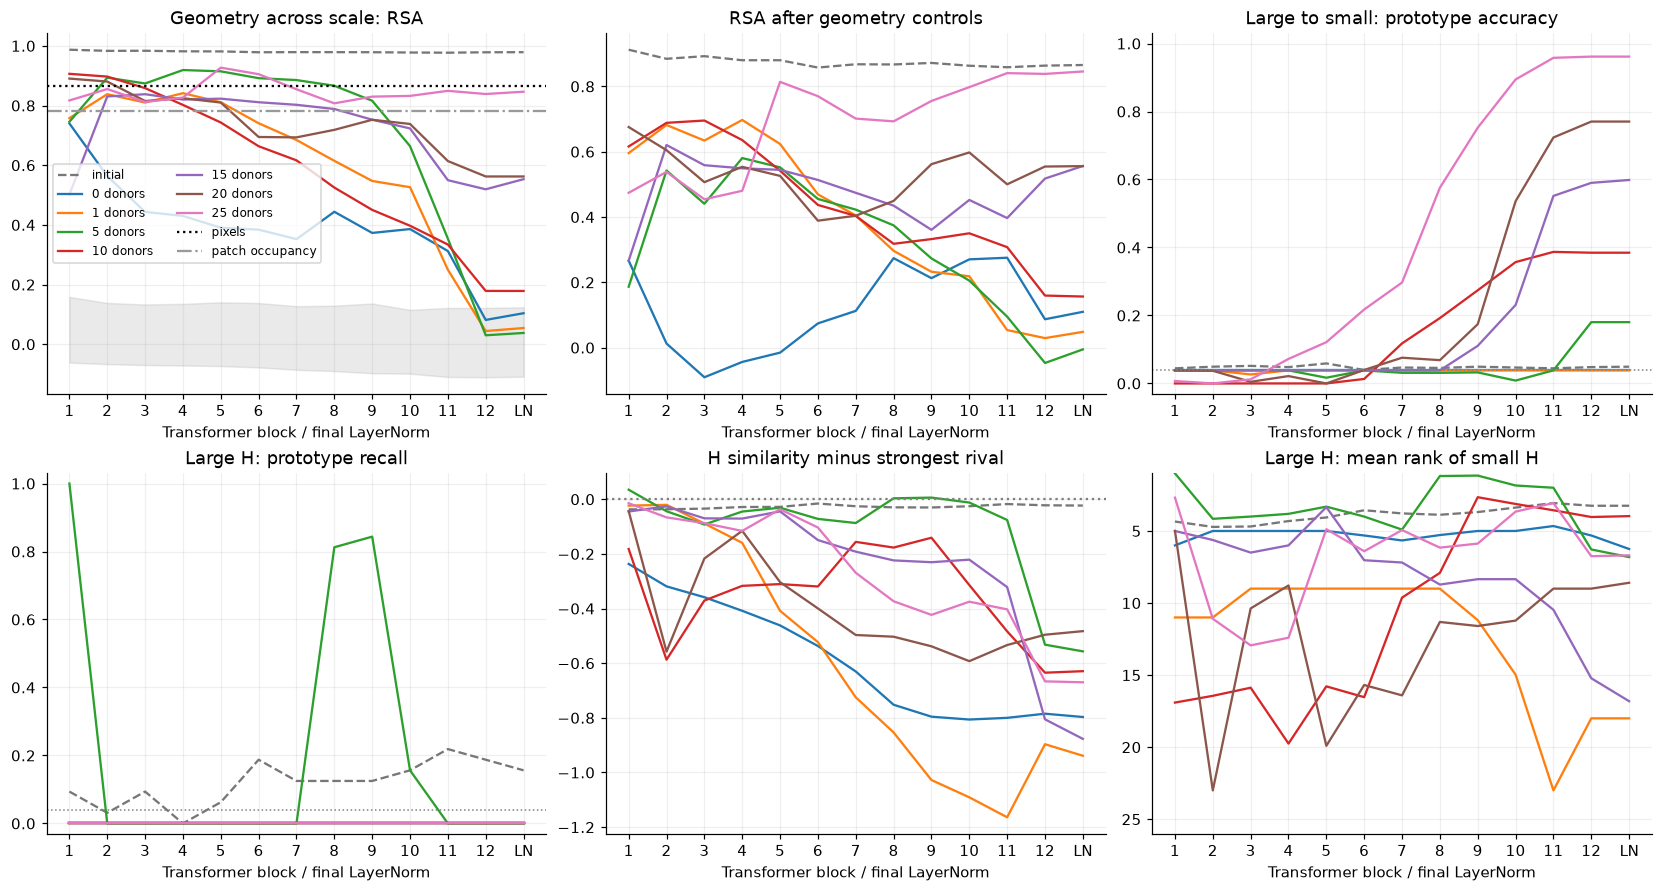

In [10]:
colors_rep = {run: plt.get_cmap('tab10')(i) for i, run in enumerate(representation_runs[1:])}
colors_rep['initial'] = '#777777'
xx = np.arange(13)
fig, axes = plt.subplots(2, 3, figsize=(15, 8), layout='constrained')
for run, result in representations.items():
    label = 'initial' if run == 'initial' else str(int(run[-2:])) + ' donors'
    style = '--' if run == 'initial' else '-'
    color = colors_rep[run]
    for ax, key in zip(axes[0, :2], ['rsa', 'partial_rsa']):
        ax.plot(xx, result[key], style, color=color, label=label)
    axes[0, 2].plot(xx, result['retrieval'].mean(1), style, color=color, label=label)
    axes[1, 0].plot(xx, result['retrieval'][:, H_INDEX], style, color=color)
    axes[1, 1].plot(xx, result['h_margin'], style, color=color)
    axes[1, 2].plot(xx, result['h_rank'], style, color=color)
null = representations['big_25']['null_bounds']
axes[0, 0].fill_between(xx, null[:, 0], null[:, 1], color='gray', alpha=.16)
axes[0, 0].axhline(rsa(*pixel_rdms), color='black', ls=':', label='pixels')
axes[0, 0].axhline(rsa(*occupancy_rdms), color='#999999', ls='-.', label='patch occupancy')
titles = ['Geometry across scale: RSA', 'RSA after geometry controls', 'Large to small: prototype accuracy',
          'Large H: prototype recall', 'H similarity minus strongest rival', 'Large H: mean rank of small H']
for ax, title in zip(axes.flat, titles):
    ax.set(title=title, xlabel='Transformer block / final LayerNorm', xticks=xx, xticklabels=layers)
    ax.grid(alpha=.2)
for ax in [axes[0, 2], axes[1, 0]]:
    ax.set_ylim(-.03, 1.03)
    ax.axhline(1/26, color='gray', ls=':', lw=1)
axes[1, 1].axhline(0, color='gray', ls=':')
axes[1, 2].set_ylim(26, 1)
axes[0, 0].legend(fontsize=8, ncols=2)
savefig(fig, 'layer_patterns')


Run       original H recall   corrected H recall   corrected p(H)
big_00                 0.000                  nan              nan
big_01                 0.000                0.000         0.000000
big_05                 0.000                0.000         0.006184
big_10                 0.000                0.000         0.000354
big_15                 0.000                0.000         0.000128
big_20                 0.000                0.000         0.002557
big_25                 0.000                0.000         0.000333


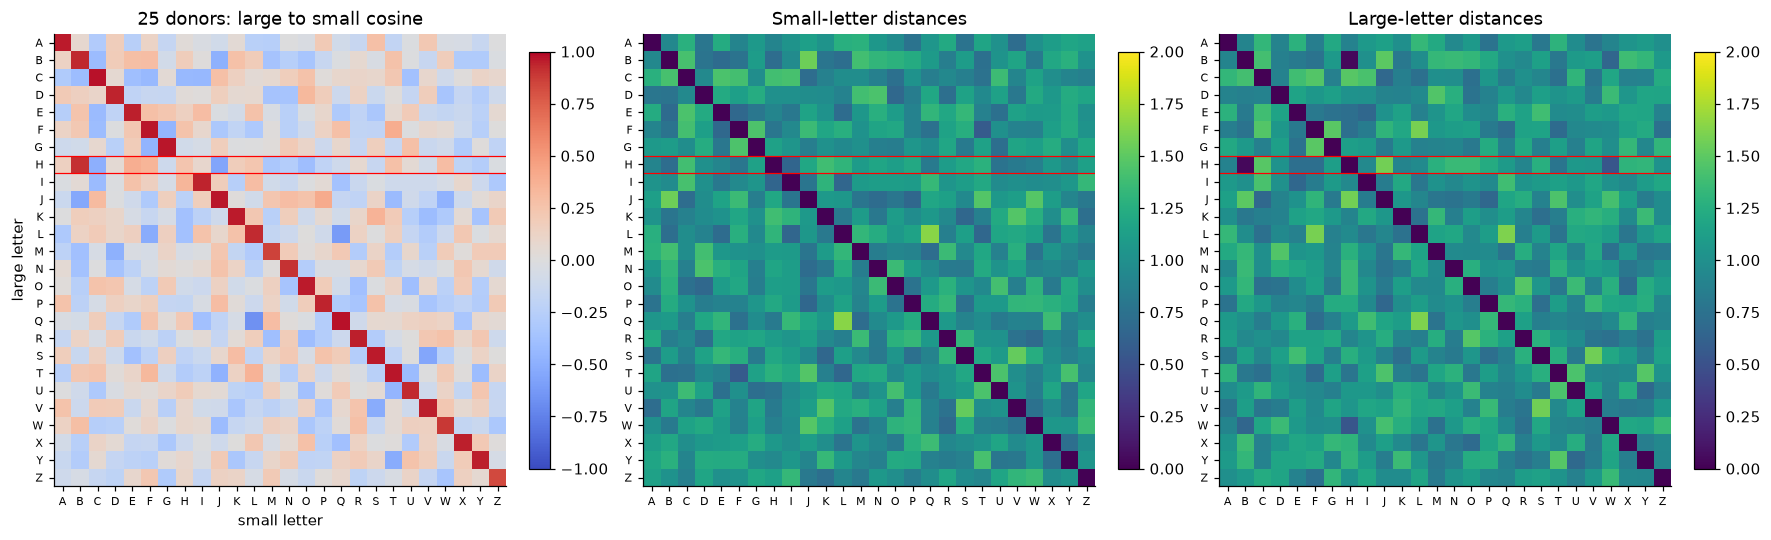

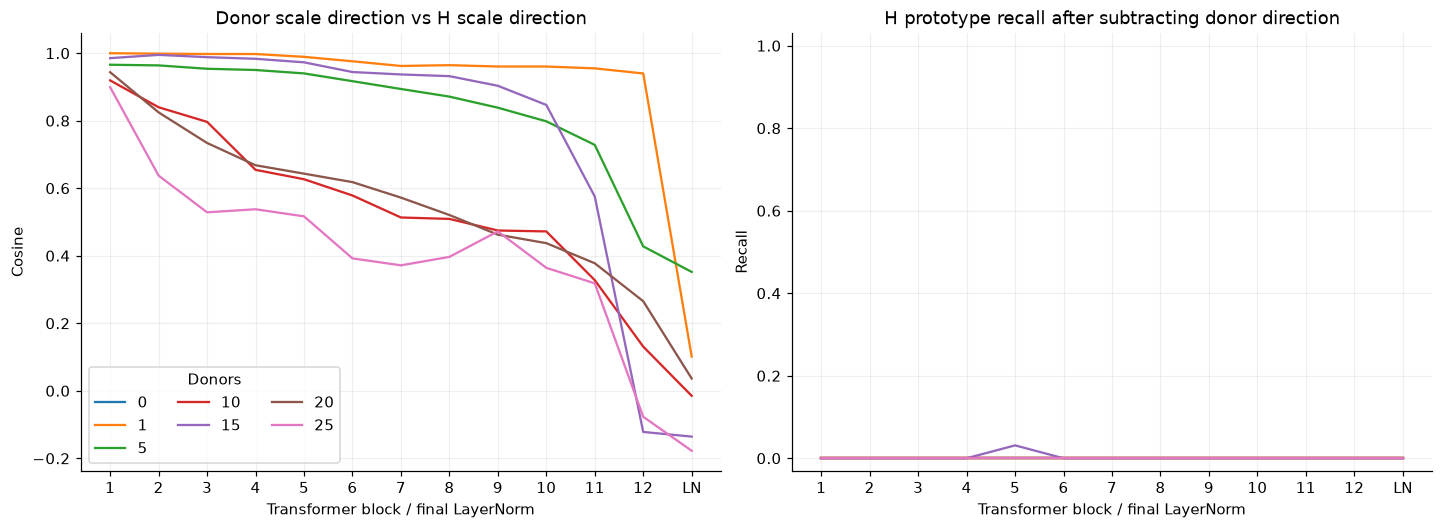

In [11]:
run = 'big_25'
result = representations[run]
means = result['means'][-1]
center = means[:, 0].mean(axis=0)
cross_similarity = unit(means[:, 1]-center) @ unit(means[:, 0]-center).T
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5), layout='constrained')
for ax, matrix, title in zip(axes, [cross_similarity, result['rdms'][-1, 0], result['rdms'][-1, 1]],
                             ['25 donors: large to small cosine', 'Small-letter distances', 'Large-letter distances']):
    is_cross = ax is axes[0]
    im = ax.imshow(matrix, cmap='coolwarm' if is_cross else 'viridis',
                   vmin=-1 if is_cross else 0, vmax=1 if is_cross else 2)
    ax.set(title=title, xticks=np.arange(26), yticks=np.arange(26),
           xticklabels=list(LETTERS), yticklabels=list(LETTERS))
    ax.tick_params(labelsize=7)
    ax.axhline(H_INDEX-.5, color='red', lw=.8)
    ax.axhline(H_INDEX+.5, color='red', lw=.8)
    fig.colorbar(im, ax=ax, shrink=.7)
axes[0].set(xlabel='small letter', ylabel='large letter')
savefig(fig, 'letter_geometry')

fig, axes = plt.subplots(1, 2, figsize=(13, 4.7), layout='constrained')
for run in representation_runs[1:]:
    result = representations[run]
    axes[0].plot(xx, result['direction_cosine'], label=str(int(run[-2:])), color=colors_rep[run])
    axes[1].plot(xx, result['corrected_retrieval'][:, H_INDEX], color=colors_rep[run])
axes[0].set(title='Donor scale direction vs H scale direction', ylabel='Cosine')
axes[1].set(title='H prototype recall after subtracting donor direction', ylabel='Recall', ylim=(-.03, 1.03))
for ax in axes:
    ax.set(xlabel='Transformer block / final LayerNorm', xticks=xx, xticklabels=layers)
    ax.grid(alpha=.2)
axes[0].legend(title='Donors', ncols=3)
savefig(fig, 'scale_direction')
print('Run       original H recall   corrected H recall   corrected p(H)')
for run in representation_runs[1:]:
    result = representations[run]
    print(f"{run:10s} {result['raw_h_recall']:17.3f} {result['corrected_h_recall']:20.3f} {result['corrected_h_p']:16.6f}")


## Знакомый масштаб и перенос на другие классы

Общий RSA при 25 донорах в основном описывает буквы, которые уже были большими при обучении.
Ниже качество классификатора разделено на доноров и остальные буквы. Использованы 64 диагностических
положения, поэтому значения могут немного отличаться от исходного теста на 256 положениях.

Справа — именно «сходство сходств» для H: сравнение её расстояний до остальных 25 букв
внутри маленького и внутри большого масштаба. Это описательная корреляция по прототипам.
Высокое значение не равнозначно правильному ответу классификатора.

Donors | seen large recall | unseen large recall | H relation RSA (LN)
     0 |               nan |              0.0385 | 0.0377
     1 |            1.0000 |              0.0000 | 0.0608
     5 |            0.9563 |              0.0000 | -0.1608
    10 |            1.0000 |              0.0000 | 0.4177
    15 |            1.0000 |              0.0185 | 0.1677
    20 |            1.0000 |              0.0026 | -0.0346
    25 |            1.0000 |              0.0000 | 0.3992
big_05, block 1: H prototype recall = 1.0 ; false positive rate for H = 0.91625


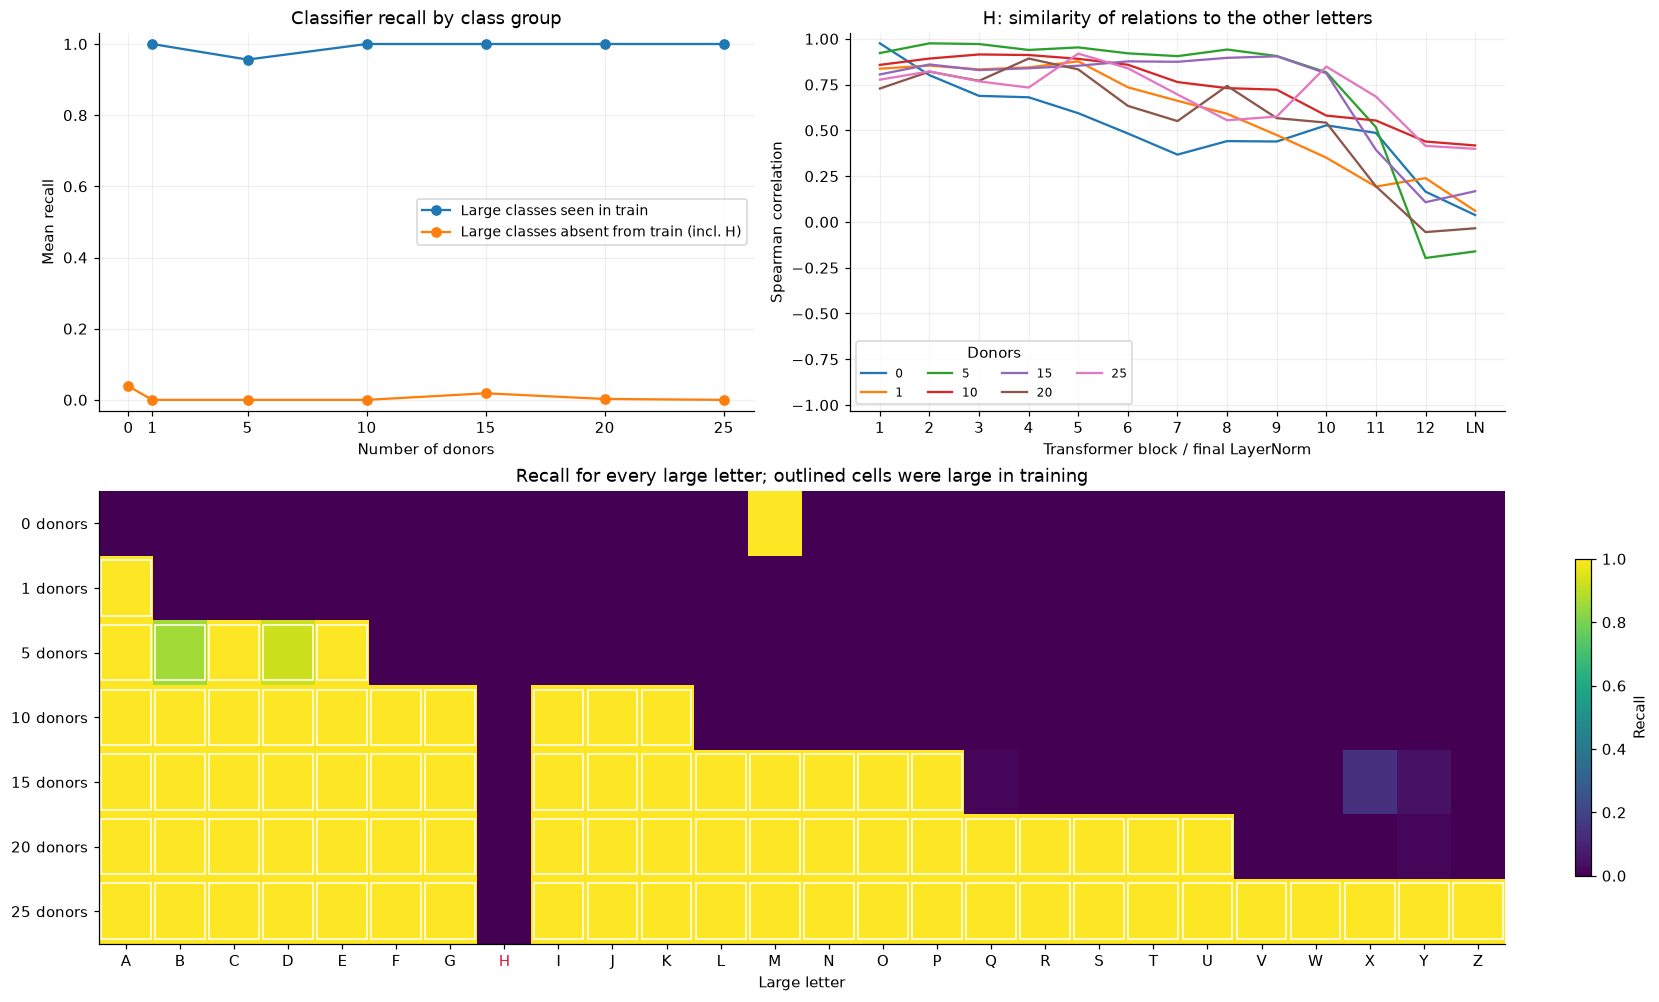

In [12]:
fig = plt.figure(figsize=(15, 9), layout='constrained')
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.2])
ax_group, ax_rel = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1])
ax_heat = fig.add_subplot(gs[1, :])
group_seen, group_unseen, heat = [], [], []
relations = {}
for run in representation_runs[1:]:
    result = representations[run]
    is_donor = np.array([c in provenance[run]['donors'] for c in LETTERS])
    accuracy = result['classifier_accuracy'][:, 1]
    group_seen.append(accuracy[is_donor].mean() if is_donor.any() else np.nan)
    group_unseen.append(accuracy[~is_donor].mean())
    heat.append(accuracy)
    relation = np.array([correlation(ranks(a[H_INDEX, np.arange(26) != H_INDEX]),
                                     ranks(b[H_INDEX, np.arange(26) != H_INDEX]))
                          for a, b in result['rdms']])
    relations[run] = relation
    ax_rel.plot(xx, relation, color=colors_rep[run], label=str(int(run[-2:])))
ax_group.plot(counts, group_seen, 'o-', label='Large classes seen in train')
ax_group.plot(counts, group_unseen, 'o-', label='Large classes absent from train (incl. H)')
ax_group.set(title='Classifier recall by class group', xlabel='Number of donors',
             xticks=counts, ylim=(-.03, 1.03), ylabel='Mean recall')
ax_group.grid(alpha=.2)
ax_group.legend(fontsize=9)
ax_rel.set(title='H: similarity of relations to the other letters', ylabel='Spearman correlation',
           xlabel='Transformer block / final LayerNorm', xticks=xx, xticklabels=layers, ylim=(-1.03, 1.03))
ax_rel.grid(alpha=.2)
ax_rel.legend(title='Donors', ncols=4, fontsize=8)
im = ax_heat.imshow(heat, aspect='auto', vmin=0, vmax=1, cmap='viridis')
ax_heat.set(title='Recall for every large letter; outlined cells were large in training',
            xticks=np.arange(26), xticklabels=list(LETTERS), yticks=np.arange(7),
            yticklabels=[str(k)+' donors' for k in counts], xlabel='Large letter')
from matplotlib.patches import Rectangle
for row, run in enumerate(representation_runs[1:]):
    for column, c in enumerate(LETTERS):
        if c in provenance[run]['donors']:
            ax_heat.add_patch(Rectangle((column-.46, row-.43), .92, .86, fill=False, edgecolor='white', lw=1))
ax_heat.get_xticklabels()[H_INDEX].set_color('crimson')
fig.colorbar(im, ax=ax_heat, shrink=.7, label='Recall')
savefig(fig, 'seen_and_unseen')
print('Donors | seen large recall | unseen large recall | H relation RSA (LN)')
for run, seen, unseen in zip(representation_runs[1:], group_seen, group_unseen):
    print(f"{int(run[-2:]):6d} | {seen:17.4f} | {unseen:19.4f} | {relations[run][-1]:.4f}")
print('big_05, block 1: H prototype recall =', representations['big_05']['retrieval'][0, H_INDEX],
      '; false positive rate for H =', representations['big_05']['h_false_positive'][0])


## Что получилось

1. В итоговом исходном тесте **большая H не распознана ни разу во всех семи условиях** (0 из 256).
   При 25 донорах 256 из 256 больших H классифицируются как B; маленькие буквы распознаются на 99.970%.
2. При 25 донорах все 25 знакомых больших классов правильно сопоставляются с маленькими прототипами
   во всех 32 отложенных положениях. Для H результат 0/32; её маленький прототип имеет средний ранг 6.69.
   Сходство общих отношений между буквами (RSA=0.846) не означает переноса на H.
3. Необученная сеть имеет RSA=0.979. Даже после выбранных геометрических контролей RSA составляет
   0.865 у необученной и 0.846 у модели с 25 донорами. Само по себе это сходство уже возникает
   из изображений и устройства случайной сети; называть его выученным пониманием масштаба нельзя.
4. Вычитание среднего изменения представления, оценённого только по донорам, не исправляет H
   ни в одном условии. Не поддержана конкретная гипотеза о **простом общем аддитивном сдвиге**,
   достаточном для коррекции; это не исключает нелинейное или зависимое от формы преобразование.
5. Ранние всплески recall требуют проверки остальных классов. В baseline эпоха 3 даёт H recall=100%,
   но accuracy маленьких всего 10.55%. Аналогично, в первом блоке big_05 прототип H часто выбирается
   для чужих больших букв: H recall=100%, но false positive rate=91.6%. Это отсутствие различения классов.
6. Результат устойчив к выбранным сдвигам: корреляции RDM между двумя половинами положений выше 0.938.
   Это проверка устойчивости внутри данного набора, а не оценка воспроизводимости по seed.

Наблюдения согласуются с тем, что обучение хорошо согласует два масштаба **для знакомых сочетаний
буква–масштаб**, а переноса на H в этой постановке не возникло. Они не доказывают точного механизма
внутри сети и не означают, что любой ViT не способен к такому переносу.

Относительная вероятность H иногда растёт, когда абсолютная p(H) мала и recall остаётся нулевым:
подавление других small-only классов уменьшает знаменатель. Поэтому графики показывают оба показателя.

## Границы вывода

Проверяется один seed, один шрифт, один контрольный класс H и два размера.
Порядок доноров фиксирован: число больших букв смешано с их составом.
У донора 64 маленьких и 64 больших изображения за эпоху, у остальных 128 маленьких.
Условия заканчиваются на разных эпохах. Условие с 15 донорами не достигло 99% на маленьких.
Веса есть только последних состояний: паттерны активации прошлых эпох восстановить нельзя.

RSA, близость прототипов и эффект вычитания delta отвечают на разные вопросы.
Даже высокое сходство геометрии не доказывает наличие абстрактного понятия масштаба.
Следующий строгий опыт должен менять независимо масштаб, толщину штриха/массу и занятость патчей,
повторяться с другими контрольными буквами, порядками доноров и seed.

## Косинусная близость маленькой и большой H по числу доноров

Сравниваются CLS-векторы после финального LayerNorm, перед классификатором.
Для каждого размера сначала усредняем активации H по 64 общим смещениям,
затем считаем `cos(mean(z_H64), mean(z_H128))`, без центрирования по другим буквам.
Это косинус средних векторов, а не средний косинус отдельных пар изображений и не RSA.

Точки соответствуют последним сохранённым моделям; эпохи остановки различаются.
Ячейку можно запускать отдельно: она читает готовые активации из `representations.npz`.


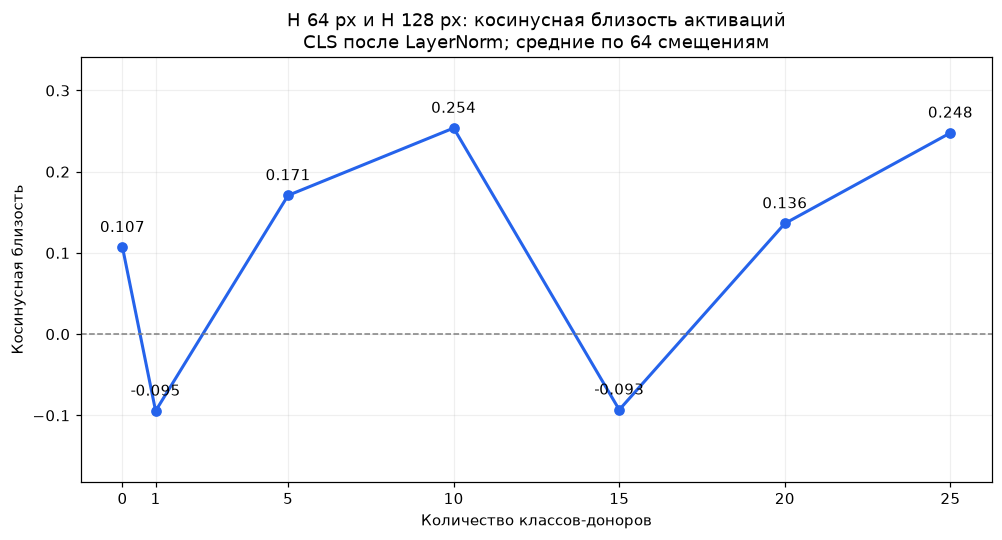

Доноров | cosine(H64, H128)
      0 | 0.106987
      1 | -0.094552
      5 | 0.170809
     10 | 0.253745
     15 | -0.093165
     20 | 0.136228
     25 | 0.247821


In [13]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
analysis_dir = root / "results" / "letters_scale_epochwise" / "analysis"

with np.load(analysis_dir / "representations.npz", allow_pickle=False) as saved:
    runs_h = sorted(key.removesuffix("__means") for key in saved.files
                    if key.startswith("big_") and key.endswith("__means"))
    h_index = saved["letters"].tolist().index("H")
    means_h = np.stack([saved[run + "__means"][-1, h_index] for run in runs_h]).astype(np.float64)
    positions_h = len(saved["paired_shifts"])

small_h = means_h[:, 0]
large_h = means_h[:, 1]
cosine_h = np.sum(small_h * large_h, axis=1) / (
    np.linalg.norm(small_h, axis=1) * np.linalg.norm(large_h, axis=1)
)
donor_counts_h = [int(run.split("_")[-1]) for run in runs_h]

fig, ax = plt.subplots(figsize=(9, 4.8), layout="constrained")
ax.plot(donor_counts_h, cosine_h, "o-", color="#2563eb", linewidth=2, markersize=6)
ax.axhline(0, color="gray", linestyle="--", linewidth=1)
for count, value in zip(donor_counts_h, cosine_h):
    ax.annotate(f"{value:.3f}", (count, value), xytext=(0, 10),
                textcoords="offset points", ha="center", fontsize=10)
ax.set(title=f"H 64 px и H 128 px: косинусная близость активаций\n"
             f"CLS после LayerNorm; средние по {positions_h} смещениям",
       xlabel="Количество классов-доноров", ylabel="Косинусная близость",
       xticks=donor_counts_h)
ax.margins(y=0.25)
ax.grid(alpha=0.2)
fig.savefig(analysis_dir / "h_scale_cosine_by_donors.png", dpi=170, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Доноров | cosine(H64, H128)")
for count, value in zip(donor_counts_h, cosine_h):
    print(f"{count:7d} | {value:.6f}")


## Вероятность H после исключения классов-доноров

Для каждого тестового изображения большой H считаем
`q = p(H) / sum(p(классов, не входящих в доноры))`, затем `score = q * (26 - n) / 26`.
На графике — среднее score по 256 изображениям последней сохранённой эпохи каждого условия.
Деление выполняется **до усреднения**. Знаменатель суммируется напрямую, чтобы избежать
потери точности при вычислении `1 - sum(p(доноров))`.

Поправка учитывает число оставшихся классов; число тестовых изображений остаётся 256.
При равномерном распределении среди оставшихся классов score равен `1/26` для любого n.
При **n=25** остаётся только H: q всегда равен 1 и score всегда равен `1/26`.
Эта точка вырождена и не измеряет качество распознавания. Исходная p(H) показана для сравнения.
Ячейку можно запускать отдельно; она читает сохранённые вероятности, обучение не требуется.


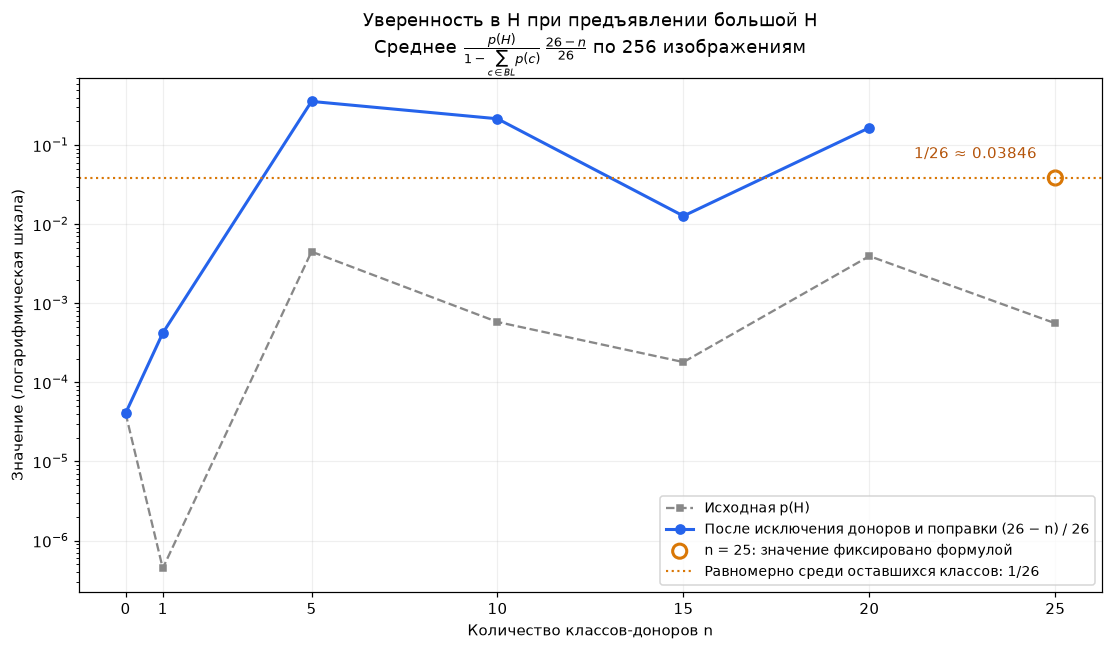

Доноры  Эпоха      p(H)     p(H | не донор)   С поправкой   Масса не-доноров
     0     90   0.0000407          0.000041      0.000041         1.0000000
     1    100   0.0000004          0.000437      0.000421         0.0010183
     5    120   0.0045020          0.442847      0.357684         0.0097634
    10     90   0.0005805          0.350662      0.215792         0.0014217
    15    120   0.0001806          0.030057      0.012716         0.0124094
    20     95   0.0039572          0.720818      0.166343         0.0043983
    25    100   0.0005585          1.000000      0.038462         0.0005585


In [14]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
results_dir = root / "results" / "letters_scale_epochwise"
confidence_rows = []

for file in sorted(results_dir.glob("big_*_probabilities.npz")):
    with np.load(file, allow_pickle=False) as saved:
        classes = saved["classes"].tolist()
        donors = saved["donors"].tolist()
        h = classes.index("H")
        mask = (saved["labels"] == h) & (saved["heights"] == 128)
        probabilities_h = saved["probabilities"][-1, mask].astype(np.float64)
        remaining = np.array([letter not in donors for letter in classes])
        assert len(classes) == 26 and len(probabilities_h) == 256 and remaining[h]
        mass_remaining = probabilities_h[:, remaining].sum(axis=1)
        assert np.all(mass_remaining > 0)
        conditional_h = probabilities_h[:, h] / mass_remaining
        adjusted_h = conditional_h * remaining.sum() / len(classes)
        confidence_rows.append((len(donors), int(saved["epochs"][-1]),
                                probabilities_h[:, h].mean(), conditional_h.mean(),
                                adjusted_h.mean(), mass_remaining.mean()))

confidence_values = np.array(confidence_rows)
n_donors = confidence_values[:, 0].astype(int)
raw_confidence_h = confidence_values[:, 2]
adjusted_confidence_h = confidence_values[:, 4]
regular = n_donors < 25

fig, ax = plt.subplots(figsize=(10, 5.8), layout="constrained")
ax.plot(n_donors, raw_confidence_h, "s--", color="#888888", markersize=4,
        label="Исходная p(H)")
ax.plot(n_donors[regular], adjusted_confidence_h[regular], "o-", color="#2563eb",
        linewidth=2, label="После исключения доноров и поправки (26 − n) / 26")
ax.scatter(n_donors[~regular], adjusted_confidence_h[~regular], s=85,
           facecolors="none", edgecolors="#d97706", linewidths=2,
           label="n = 25: значение фиксировано формулой")
ax.axhline(1/26, color="#d97706", linestyle=":", linewidth=1.4,
           label="Равномерно среди оставшихся классов: 1/26")
ax.annotate("1/26 ≈ 0.03846", (25, 1/26), xytext=(-12, 13),
            textcoords="offset points", ha="right", color="#b45309", fontsize=10)
ax.set(title="Уверенность в H при предъявлении большой H\n"
             r"Среднее $\frac{p(H)}{1-\sum_{c\in BL} p(c)}\,\frac{26-n}{26}$ по 256 изображениям",
       xlabel="Количество классов-доноров n", ylabel="Значение (логарифмическая шкала)",
       xticks=n_donors, yscale="log")
ax.grid(alpha=0.2)
ax.legend(fontsize=9, loc="lower right")
fig.savefig(results_dir / "analysis" / "h_confidence_adjusted_by_donors.png", dpi=170, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Доноры  Эпоха      p(H)     p(H | не донор)   С поправкой   Масса не-доноров")
for n, epoch, raw, conditional, adjusted, mass in confidence_rows:
    print(f"{n:6d} {epoch:6d} {raw:11.7f} {conditional:17.6f} {adjusted:13.6f} {mass:17.7f}")
